# Region-based Cell Type Selection

This tutorial demonstrates how to use regional prediction to identify cell types found within a subregion of interest with in the hypothalamus.

In this notebook, we will:
1. Identify L4 cell types with DMH predicted as their top region via their descriptive annotation
2. Load and handle the region relative mass table
3. Identify L4 cell types with relative mass within the DMH
4. Visualize DMH populations on a single-cell UMAP

Requirements:
1. `matplotlib`, `pandas`, and `scanpy` python packages.
2. HypoMap3D's region relative mass table and full single cell object. 

This tutorial assumes basic familiarity with Scanpy and AnnData objects.

In [2]:
# Enable automatic reloading of modules during interactive work (optional)
%load_ext autoreload
%autoreload 2

In [ ]:
import matplotlib.pyplot as plt

import pandas as pd
import scanpy as sc

# Conversion factor: millimeters to inches (for publication-style figures)
MM = 1 / 25.4

In [ ]:
# Set the path to each the required objects
FP_SC_ANNDATA = r'REPLACE FILEPATH HERE'
FP_REGION_TABLE = r'REPLACE FILEPATH HERE'

### Finding cell types with DMH as the top region

Clusters are annotated with their to region from L3 towards. First, we will look for L4 cell types with DMH in the name.

This is a quick and dirty method, and is not recommended as cell types can cover multiple regions.

In [5]:
# First we load the full HypoMap3D single-cell object
adata = sc.read_h5ad(FP_SC_ANNDATA)
adata

AnnData object with n_obs × n_vars = 1564064 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'sex_per_sample_inferred', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'L1_ID', 'L2_ID', 'L3_ID', 'L4_ID', 'L5_ID', 'L1_descr', 'L2_descr', 'L3_descr', 'L4_descr', 'L5_descr', 'L1_abc_like', 'L2_abc_like', 'L3_abc_like', 'L4_abc_like', 'L5_abc_like'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_spatial_umap', 'X_umap'

In [48]:
# Full list of annotation on L4
L4_celltypes = adata.obs['L4_descr'].cat.categories

# Filter this list to only those with DMH
L4_dmh_celltypes = [annotation for annotation in L4_celltypes if 'DMH' in annotation]

print(f"{len(L4_dmh_celltypes)} cell types have DMH as the top region.")

54 cell types have DMH as the top region.


### Finding cell types predicted within the DMH using relative mass

We provide a table with the relative mass contribution of all hypothalamic subregions for every cluster of the taxonomy.

We will use this to identify cell types that overlap with the DMH with > 10% relative mass contribution.

In [49]:
# Load the region table, we will set the descr name as the index
df_region_relmass = pd.read_csv(FP_REGION_TABLE, index_col='celltype_descr')

# First filter the table to only L4 cell types
df_L4_region_relmass = df_region_relmass[
    df_region_relmass['celltype_id'].str.contains('4-')
]

df_L4_region_relmass.head(3)

,celltype_id,celltype_abc_like,flag,TMv,IF,PT,AAA,IGL,PVa,PVH,...,MMp,MMd,PN,IPR,IPC,IPL,IPI,IPDM,IPDL,IPRL
celltype_descr,,,,,,,,,,,,,,,,,,,,,
Gb4-319 MPO Meis1.Cpa6,Gb4-319,Gb4-319 SI-MPO-LPO Lhx8 GABA_2-1,NaN,0.000337,0.000025,0.000032,0.004646,2.159963e-07,0.000306,0.001380,...,0.000000e+00,0.000027,3.548311e-09,1.785852e-07,6.662969e-08,9.183548e-09,2.557501e-07,0.000000e+00,0.000000,5.172620e-09
Gb4-320 MPO Meis1.Popdc3,Gb4-320,Gb4-320 SI-MPO-LPO Lhx8 GABA_2-2,Signal and shape,0.000018,0.000000,0.000006,0.000127,0.000000e+00,0.000028,0.004847,...,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00
Gb4-321 MPO Meis1.Hcrtr2,Gb4-321,Gb4-321 SI-MPO-LPO Lhx8 GABA_2-3,Shape,0.000221,0.000096,0.000029,0.000887,1.195047e-05,0.000025,0.001427,...,3.432034e-13,0.000009,2.212906e-07,1.365827e-04,2.275031e-08,9.759833e-09,1.028890e-07,2.278880e-09,0.000006,8.036694e-06


In [50]:
# Let's then filter to cell types with > 0.1 relmass for the DMH
L4_dmh_celltypes_by_relmass = df_L4_region_relmass.loc[
    df_L4_region_relmass['DMH'] > 0.1,
    'DMH'
]

L4_dmh_celltypes_by_relmass = L4_dmh_celltypes_by_relmass.sort_values(ascending=False)
L4_dmh_celltypes_by_relmass = L4_dmh_celltypes_by_relmass.index.tolist()


print(f"{len(L4_dmh_celltypes_by_relmass)} cell types have DMH with >0.1 relmass - the top 3 are: {L4_dmh_celltypes_by_relmass[:3]}")

63 cell types have DMH with >0.1 relmass - the top 3 are: ['Gl4-206 DMH Nr2f1.Sh3bgr', 'Gl4-202 DMH Pdyn.Neurod1', 'Gl4-204 DMH Pdyn.Areg']


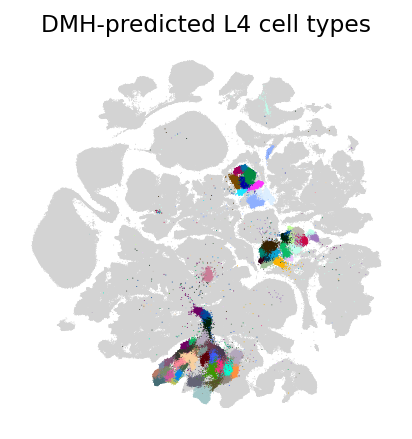

In [55]:
# Visualize marker score and cluster location on UMAP
fig, ax = plt.subplots(1, 1, figsize=(90*MM, 90*MM), dpi=140)

# Marker score -------------------------------------------------------------- #
sc.pl.umap(
    adata,
    color='L4_descr', groups=L4_dmh_celltypes_by_relmass,
    ax=ax,
    show=False,
    frameon=False,
    palette=sc.pl.palettes.default_102,
    title='DMH-predicted L4 cell types',
    legend_loc=None,
    s=1
)

plt.show()
plt.close()